# 02d · ACDC v3b: one cut-off per receiver, more situation pairs, zero tolerance

**What happened before.** Edge-by-edge ACDC overfits the pairs it is tested on:
* v1 (8 + 8 pairs, loss on the mean): 726 edges; F ≈ 0.85 on its own pairs, but 0.15 (situation) and 0.54
  (phrase) on unseen pairs, while the 9600-edge candidate gives ≈ 1 there;
* v2 (16 + 16 pairs, per-pair loss, cap = start + 0.02, monitor on 16 + 16 other pairs): after only 8 receivers
  the monitor F fell from 1.01 / 0.95 (candidate) to 0.77 / 0.64 while the loss on its own pairs stayed flat.
  Stopped. Reason: even the good candidate has ≈ 0.3 noise per pair, so with 16 pairs the loss is uncertain by
  ≈ 0.08, much more than the τ = 0.005 of each of the thousands of decisions.

**v3: fewer decisions, on many more pairs.**
* The **order** of the edges into each receiver comes from the EAP-IG scores (computed on all discovery pairs;
  the candidate built from them generalises).
* For each receiver ACDC chooses only **how many** of its strongest incoming edges to keep: try k = 0, then a
  binary search on k (≈ log2(n) tests). ≈ 57 decisions in total instead of thousands of free ones.
* Because there are few tests, ACDC uses **all correct discovery pairs** except those kept for the monitor
  and the validation (see v3b below). Loss per pair, monitor every 4 receivers, as in v2.

**v3 (notebook 02c) was stopped after 13 receivers**: phrase stayed stable on the monitor pairs (0.93 → 0.85-0.87),
but situation fell 0.99 → 0.89 → 0.75 → 0.73 (biggest step when the whole m24 was removed, while the loss on the
ACDC pairs did not change). Situation has far fewer correct token-matched pairs than phrase, and v3 kept 16 for
the monitor and 24 for validation, leaving few for ACDC.

**v3b changes:** situation is validated on the 28 held-out pairs only (phrase on 24 unused discovery pairs), the
monitor uses 8 + 8 pairs, so ACDC gets more situation pairs; two runs in a row:
1. **zero tolerance**: τ = 0 and cap = starting loss: an edge goes only if the circuit does not get worse;
2. τ = 0.005, cap = start + 0.02, starting from the circuit of run 1 (a smaller circuit, for the size ↔
   faithfulness trade-off).

Results go to `02_acdc/<model>/v3b/`; v1 is re-evaluated on the same validation pairs for the comparison.

**GPU:** L4 or A100 (the pairs are kept in memory in chunks of 32; a T4 has too little memory for many chunks:
lower `N_ACDC_MAX` there). About 1 h on an A100. Progress is saved on Drive after every receiver.

## Setup

In [1]:
# Get (or update) the code from GitHub
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes

In [2]:
import os, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src.model import load_model, model_info, DEV_MODEL, MAIN_MODEL
from src.prompts import load_dataset, make_pairs, data_tag
from src.patching import score_pairs, keep_correct, mean_and_se
from src.eap import build_graph, top_k_mask, random_mask, edge_table, prune_dangling
from src.acdc import BatchEvaluator, MultiEvaluator, acdc_cutoff, faithfulness_many
from src.utils import mount_drive, results_dir, cached, set_seed

# ---------------- settings ----------------
MODEL = MAIN_MODEL          # DEV_MODEL (3B) for quick tests
DATA = "v2"                 # dataset version: "v1" (pilot) or "v2" (data/make_dataset_v2.py)
N_ACDC_MAX = 64             # at most this many pairs per experiment for ACDC (all other correct discovery pairs)
LOSS = "per_pair"           # mean over pairs of |1 - F|  (v1: "mean")
TAUS = [0.0, 0.005]         # run in this order, each from the previous circuit
CAP_MARGINS = {0.0: 0.0, 0.005: 0.02}   # cap = starting loss + margin (0: never worse than the candidate)
N_MON = 8                   # pairs per experiment to monitor generalisation during the run (not used for decisions)
N_VAL_DISC = {"situation": 0, "phrase": 24}   # unused discovery pairs kept for validation (situation: held-out only)
N_HELD_MAX = 64             # at most this many held-out pairs per experiment for validation
TARGET_F = 0.9
# ------------------------------------------
TAG = MODEL.split("/")[-1] + data_tag(DATA)   # v1 keeps the old folders
SUB = f"02_acdc/{TAG}/v3b"
SUB_V1 = f"02_acdc/{TAG}"
SUB_1B = f"01b_eap_ig/{TAG}"
mount_drive()
print("results go to:", results_dir(SUB))
set_seed(0)

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/02_acdc/Qwen2.5-7B-Instruct_data-v2/v3b


In [3]:
t0 = time.time()
model, tok = load_model(MODEL)
INFO = model_info(model)
G = build_graph(model)
print(MODEL, INFO, f"loaded in {(time.time() - t0) / 60:.1f} min")

# Phase 1b results
CAND = np.load(os.path.join(results_dir(SUB_1B), "candidate_mask.npy"))
SUM_1B = json.load(open(os.path.join(results_dir(SUB_1B), "summary.json")))
COMBINED = np.load(os.path.join(results_dir(SUB_1B), "mean_scores.npz"))["combined"]
print(f"candidate circuit from Phase 1b: {int(CAND.sum())} of {G.n_edges()} edges (top-{SUM_1B['k_star']})")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct {'n_layers': 28, 'n_heads': 28, 'n_kv_heads': 4, 'd_model': 3584, 'head_dim': 128} loaded in 1.2 min
candidate circuit from Phase 1b: 9600 of 23577 edges (top-9600)


## Pairs: for ACDC and for validation

In [5]:
df = load_dataset(DATA)
ACDC_PAIRS, MON_PAIRS, VAL = [], [], {"heldout": [], "discovery (unused)": []}
for e in ["situation", "phrase"]:
    disc = keep_correct(score_pairs(model, tok, make_pairs(df, tok, e)))
    if DATA != "v1":      # the same seeded shuffle as 01b
        disc = [disc[i] for i in np.random.default_rng(0).permutation(len(disc))]
    held = keep_correct(score_pairs(model, tok, make_pairs(df, tok, e, split="heldout")))
    if DATA != "v1":
        held = [held[i] for i in np.random.default_rng(1).permutation(len(held))]
    held = held[:N_HELD_MAX]
    # the last pairs are kept aside: validation and monitor; ACDC gets the rest (starting with 01b's 16)
    nv = N_VAL_DISC[e]
    val, mon, rest = disc[len(disc) - nv:], disc[len(disc) - nv - N_MON:len(disc) - nv], disc[:len(disc) - nv - N_MON]
    ACDC_PAIRS += rest[:N_ACDC_MAX]
    MON_PAIRS += mon
    VAL["discovery (unused)"] += val
    VAL["heldout"] += held
    print(f"{e:9s}: {len(disc)} correct discovery pairs: ACDC {len(rest[:N_ACDC_MAX])}, monitor {len(mon)}, "
          f"validation {len(val)} | {len(held)} held-out pairs")
print("validation:", {k: len(v) for k, v in VAL.items()})

situation: 615 correct discovery pairs: ACDC 64, monitor 8, validation 0 | 64 held-out pairs
phrase   : 484 correct discovery pairs: ACDC 64, monitor 8, validation 24 | 64 held-out pairs
validation: {'heldout': 128, 'discovery (unused)': 24}


## Sanity check

All edges → $F = 1$, no edges → $F = 0$ (exactly), and the candidate circuit gives the same $F$ per pair as in
Phase 1b (there each pair was evaluated alone; here all pairs go in one batch, so tiny float16 differences are normal).

In [8]:
EV = MultiEvaluator(model, tok, ACDC_PAIRS, G, loss=LOSS, batch=32)
F_all, F_none, F_cand = EV.faithfulness(G.valid), EV.faithfulness(np.zeros_like(G.valid)), EV.faithfulness(CAND)
CHECKS = {"all edges = 1": np.abs(F_all - 1).max() < 1e-3, "no edges = 0": np.abs(F_none).max() < 1e-3}
print(f"all edges: max |F - 1| = {np.abs(F_all - 1).max():.5f} | no edges: max |F| = {np.abs(F_none).max():.5f}")

curve = pd.read_csv(os.path.join(results_dir(SUB_1B), "faithfulness_curve.csv"))
j = list(curve.k).index(SUM_1B["k_star"])
gaps = []
for e in ["situation", "phrase"]:
    f1b = torch.load(os.path.join(results_dir(SUB_1B), f"faithfulness_{e}_{SUM_1B['n_eval']}pairs_kmax{curve.k.iloc[-1]}.pt"),
                     weights_only=False)["top"][:16, j]
    here = F_cand[EV.exp == e][:len(f1b)]
    gaps.append(abs(np.median(here) - np.median(f1b)))
    print(f"{e:9s}: F of the candidate, batched {here.mean():.3f} vs Phase 1b {f1b.mean():.3f} "
          f"(per pair the float16 batch noise is up to {np.abs(here - f1b).max():.3f})")
CHECKS["same F as Phase 1b"] = max(gaps) < 0.05      # mean over pairs; 01b may have run on another GPU (float16 differs slightly)
t0 = time.time(); START_LOSS = EV.loss(CAND); dt = time.time() - t0
CAPS = {t: float(START_LOSS) + m for t, m in CAP_MARGINS.items()}
print(f"one ACDC test = {dt:.2f} s; start loss ({LOSS}) = {START_LOSS:.3f}, mean F = "
      f"{ {k: round(v, 3) for k, v in EV.mean_F(CAND).items()} } -> caps = { {t: round(c, 4) for t, c in CAPS.items()} }")
for k, v in CHECKS.items():
    print("PASS" if v else "FAIL", k)
assert CHECKS["all edges = 1"] and CHECKS["no edges = 0"], "sanity check failed: send the output to Claude"

all edges: max |F - 1| = 0.00000 | no edges: max |F| = 0.00000
situation: F of the candidate, batched 0.894 vs Phase 1b 0.897 (per pair the float16 batch noise is up to 0.371)
phrase   : F of the candidate, batched 1.000 vs Phase 1b 1.133 (per pair the float16 batch noise is up to 1.206)
one ACDC test = 8.31 s; start loss (per_pair) = 0.228, mean F = {np.str_('phrase'): 1.065, np.str_('situation'): 0.858} -> caps = {0.0: 0.2283, 0.005: 0.2483}
PASS all edges = 1
PASS no edges = 0
FAIL same F as Phase 1b


## Run ACDC

One line per receiver: incoming edges before → after, number of tests, size and loss of the whole circuit.
The first $\tau$ takes longest; the next ones start from a smaller circuit.

In [9]:
def monitor(mask):
    # mean F per experiment on the monitor pairs (never used for ACDC's decisions)
    F = faithfulness_many(model, tok, MON_PAIRS, {"m": mask}, G, batch=16)["m"]
    exp = np.array([p.experiment for p in MON_PAIRS])
    return {e: F[exp == e].mean() for e in ["situation", "phrase"]}

MON0 = cached(f"monitor_candidate_n{N_MON}", lambda: monitor(CAND), sub=SUB)
print("monitor pairs, candidate circuit:", {k: round(float(v), 3) for k, v in MON0.items()})

RES = {}
start = CAND
for tau in TAUS:
    print(f"\n===== tau = {tau} =====")
    t0 = time.time()
    state = os.path.join(results_dir(SUB), f"acdc_cutoff_state_tau{tau}_margin{CAP_MARGINS[tau]}_{LOSS}.pt")
    RES[tau] = acdc_cutoff(EV, start, COMBINED, tau=tau, cap=CAPS[tau], state_path=state, monitor=monitor, monitor_every=4)
    print(f"tau = {tau}: {int(RES[tau]['mask'].sum())} edges, loss {RES[tau]['loss']:.3f}, "
          f"{RES[tau]['n_tests']} tests, {(time.time() - t0) / 60:.1f} min this session")
    start = RES[tau]["mask"]
del EV; torch.cuda.empty_cache()

[saved]  /content/drive/MyDrive/sarcasm/02_acdc/Qwen2.5-7B-Instruct_data-v2/v3b/monitor_candidate_n8.pt
monitor pairs, candidate circuit: {'situation': 0.774, 'phrase': 1.353}

===== tau = 0.0 =====
  logits: keep  263 of  264 incoming edges,  10 tests | circuit  9599 edges, loss 0.228 | 1.4 min
     m27: keep   44 of  200 incoming edges,   8 tests | circuit  9443 edges, loss 0.227 | 2.4 min
     a27: keep   54 of  133 incoming edges,   8 tests | circuit  9364 edges, loss 0.226 | 3.5 min
     m26: keep  136 of  161 incoming edges,   8 tests | circuit  9339 edges, loss 0.225 | 4.6 min
          monitor: {'situation': 0.797, 'phrase': 1.359}
     a26: keep  108 of  117 incoming edges,   8 tests | circuit  9330 edges, loss 0.224 | 5.7 min
     m25: keep  149 of  155 incoming edges,   9 tests | circuit  9324 edges, loss 0.223 | 6.9 min
     a25: keep    0 of   98 incoming edges,   1 tests | circuit  9141 edges, loss 0.222 | 7.1 min
     m24: keep  129 of  151 incoming edges,   8 tests | ci

### Generalisation during the run (monitor pairs)

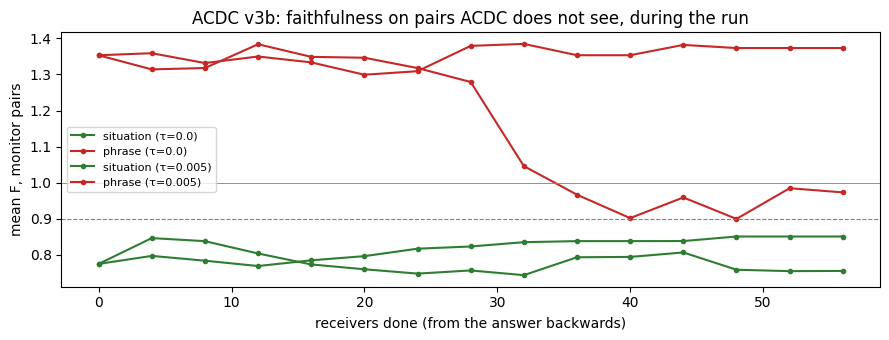

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for tau, r in RES.items():
    if not r["monitor"]: continue
    n = [0] + [m[0] for m in r["monitor"]]
    for e, c in [("situation", "#2E7D32"), ("phrase", "#C62828")]:
        ax.plot(n, [MON0[e]] + [m[2][e] for m in r["monitor"]], "-o", ms=3, color=c, label=f"{e} (τ={tau})")
ax.axhline(1, c="gray", lw=0.6); ax.axhline(0.9, c="gray", ls="--", lw=0.8)
ax.set_xlabel("receivers done (from the answer backwards)"); ax.set_ylabel("mean F, monitor pairs")
ax.set_title("ACDC v3b: faithfulness on pairs ACDC does not see, during the run"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "monitor_during_run.png"), dpi=150); plt.show()

## Validation on pairs ACDC did not see

For every ACDC circuit: the EAP-IG top-$k$ edges with the same number of edges, and random circuits of the same
size taken **inside** the candidate (3 seeds). Also the full candidate.

In [11]:
V1_PATH = os.path.join(results_dir(SUB_V1), "circuit_mask.npy")
V1 = np.load(V1_PATH) if os.path.exists(V1_PATH) else None
print("ACDC v1 circuit:", "not found" if V1 is None else f"{int(V1.sum())} edges")

def val_masks():
    m = {"candidate": CAND}
    if V1 is not None:
        m["acdc v1"] = V1
    rng = np.random.default_rng(0)
    cand_idx = np.flatnonzero(CAND)
    for tau, r in RES.items():
        k = int(r["mask"].sum())
        m[f"acdc {tau}"] = r["mask"]
        m[f"eap-ig top {tau}"] = top_k_mask(COMBINED, G, k)
        for s in range(3):
            rm = np.zeros_like(CAND); rm.flat[rng.choice(cand_idx, size=k, replace=False)] = True
            m[f"random {tau} {s}"] = rm
    return m

def run_val():
    masks = val_masks()
    out = {}
    for split, ps in VAL.items():
        F = faithfulness_many(model, tok, ps, masks, G, batch=16)
        exp = np.array([p.experiment for p in ps])
        out[split] = {name: {e: F[name][exp == e] for e in ["situation", "phrase"]} for name in masks}
    return out

t0 = time.time()
VALF = cached(f"validation_v3b_taus{'_'.join(map(str, TAUS))}_n{len(ACDC_PAIRS)}", run_val, sub=SUB)
print(f"done in {(time.time() - t0) / 60:.1f} min")

EXPS = ["situation", "phrase"]
# The held-out split uses a NEW phrase whose negative version has a different number of tokens, so it has no
# token-matched phrase pairs (edge patching needs them). So: situation is validated on held-out + unused
# discovery pairs, phrase on unused discovery pairs. VALP pools every validation pair of each experiment.
VALP = {name: {e: np.concatenate([VALF[sp][name][e] for sp in VALF]) for e in EXPS} for name in VALF["heldout"]}
WHERE = {e: " + ".join(f"{sp} ({len(VALF[sp]['candidate'][e])})" for sp in VALF if len(VALF[sp]["candidate"][e])) for e in EXPS}
print("validation pairs:", WHERE)

rows = []
for tau, r in RES.items():
    row = dict(tau=tau, edges=int(r["mask"].sum()))
    for e in EXPS:
        row[f"{e} ACDC"] = VALP[f"acdc {tau}"][e].mean()
        row[f"{e} EAP-IG"] = VALP[f"eap-ig top {tau}"][e].mean()
        row[f"{e} random"] = np.mean([VALP[f"random {tau} {s}"][e].mean() for s in range(3)])
        for sp in VALF:                                   # per split, where there are pairs
            if len(VALF[sp][f"acdc {tau}"][e]):
                row[f"{e} ACDC [{sp}]"] = VALF[sp][f"acdc {tau}"][e].mean()
    rows.append(row)
TAB = pd.DataFrame(rows)
display(TAB.round(3).T)
print(f"candidate ({int(CAND.sum())} edges):", {e: round(float(VALP['candidate'][e].mean()), 3) for e in EXPS})
if V1 is not None:
    print(f"ACDC v1   ({int(V1.sum())} edges):", {e: round(float(VALP['acdc v1'][e].mean()), 3) for e in EXPS})

ACDC v1 circuit: not found
[saved]  /content/drive/MyDrive/sarcasm/02_acdc/Qwen2.5-7B-Instruct_data-v2/v3b/validation_v3b_taus0.0_0.005_n128.pt
done in 1.8 min
validation pairs: {'situation': 'heldout (64)', 'phrase': 'heldout (64) + discovery (unused) (24)'}


,0,1
tau,0.000,0.005
edges,8147.000,5722.000
situation ACDC,0.805,0.747
situation EAP-IG,0.759,0.742
situation random,0.008,-0.001
situation ACDC [heldout],0.805,0.747
phrase ACDC,0.992,0.842
phrase EAP-IG,1.051,1.069
phrase random,0.017,-0.009
phrase ACDC [heldout],0.976,0.794


candidate (9600 edges): {'situation': 0.86, 'phrase': 1.072}


### Size vs faithfulness (validation pairs)

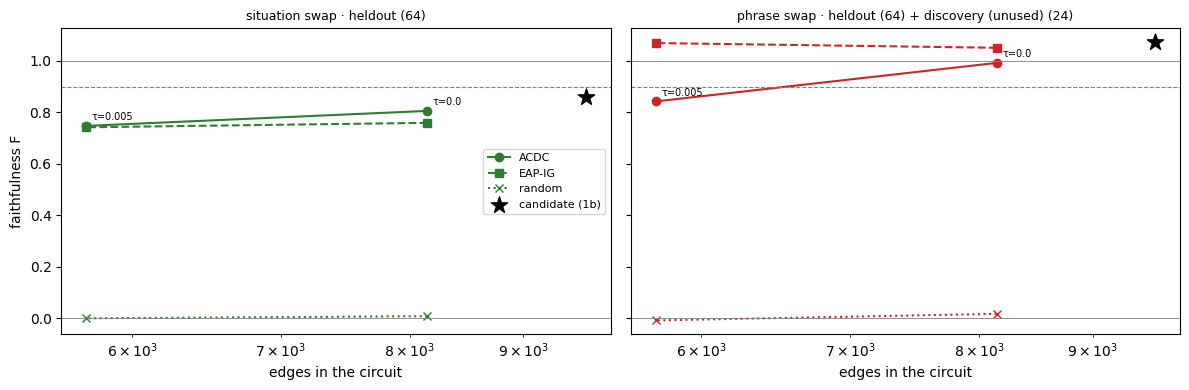

In [12]:
cols = {"situation": "#2E7D32", "phrase": "#C62828"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, e in zip(axes, EXPS):
    for kind, ls, mk in [("ACDC", "-", "o"), ("EAP-IG", "--", "s"), ("random", ":", "x")]:
        ax.plot(TAB.edges, TAB[f"{e} {kind}"], ls, marker=mk, color=cols[e], label=kind)
    ax.scatter([CAND.sum()], [VALP["candidate"][e].mean()], marker="*", s=150, color="black", label="candidate (1b)", zorder=3)
    if V1 is not None:
        ax.scatter([V1.sum()], [VALP["acdc v1"][e].mean()], marker="D", s=50, color="gray", label="ACDC v1", zorder=3)
    for _, r in TAB.iterrows():
        ax.annotate(f"τ={r.tau}", (r.edges, r[f"{e} ACDC"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.axhline(1, c="gray", lw=0.6); ax.axhline(TARGET_F, c="gray", ls="--", lw=0.8); ax.axhline(0, c="gray", lw=0.6)
    ax.set_xscale("log"); ax.set_xlabel("edges in the circuit")
    ax.set_title(f"{e} swap · {WHERE[e]}", fontsize=9)
axes[0].set_ylabel("faithfulness F"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "size_vs_faithfulness.png"), dpi=150); plt.show()

## The final circuit

The smallest ACDC circuit with mean $0.9 \le F \le 1.2$ on the validation pairs of **both** experiments.

final circuit: tau = 0.0, 8147 edges (34.6% of the graph, 84.9% of the candidate)   (target not reached: smallest tau)


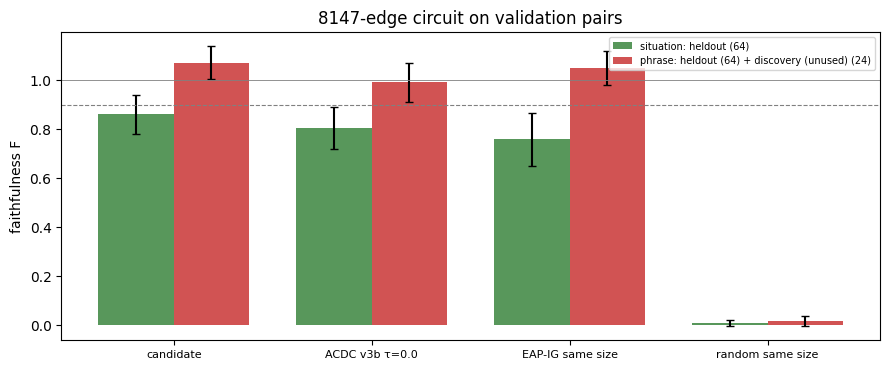

In [13]:
# above 1.2 the circuit overshoots: not faithful either
ok = [tau for tau in TAUS if all(TARGET_F <= TAB.set_index("tau").loc[tau, f"{e} ACDC"] <= 1.2 for e in EXPS)]
TAU_STAR = min(ok, key=lambda t: int(RES[t]["mask"].sum())) if ok else TAUS[0]
CIRC = RES[TAU_STAR]["mask"]
print(f"final circuit: tau = {TAU_STAR}, {int(CIRC.sum())} edges ({CIRC.sum() / G.n_edges():.1%} of the graph, "
      f"{CIRC.sum() / CAND.sum():.1%} of the candidate)" + ("" if ok else "   (target not reached: smallest tau)"))

# bar chart: candidate, ACDC, EAP-IG same size, random same size
names = [("candidate", "candidate"), (f"acdc {TAU_STAR}", f"ACDC v3b τ={TAU_STAR}"), (f"eap-ig top {TAU_STAR}", "EAP-IG same size")]
if V1 is not None:
    names.insert(1, ("acdc v1", f"ACDC v1 ({int(V1.sum())})"))
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(names) + 1)
for i, e in enumerate(EXPS):
    vals = [VALP[n][e] for n, _ in names] + [np.concatenate([VALP[f"random {TAU_STAR} {s}"][e] for s in range(3)])]
    m = [v.mean() for v in vals]; se = [v.std(ddof=1) / np.sqrt(len(v)) for v in vals]
    ax.bar(x + (i - 0.5) * 0.38, m, 0.38, yerr=1.96 * np.array(se), color=cols[e], alpha=0.8, label=f"{e}: {WHERE[e]}", capsize=3)
ax.set_xticks(x); ax.set_xticklabels([l for _, l in names] + ["random same size"], fontsize=8)
ax.axhline(1, c="gray", lw=0.6); ax.axhline(TARGET_F, c="gray", ls="--", lw=0.8)
ax.set_ylabel("faithfulness F"); ax.set_title(f"{int(CIRC.sum())}-edge circuit on validation pairs"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "final_circuit_faithfulness.png"), dpi=150); plt.show()

### Where are the edges of the final circuit?

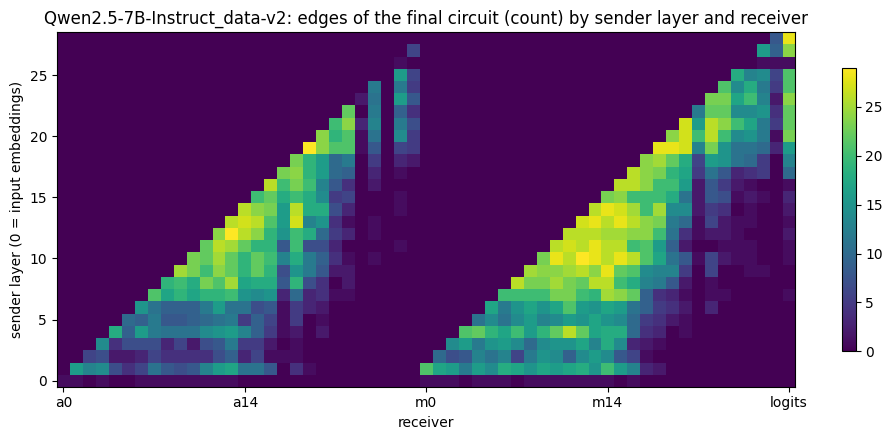

components in the circuit: 749  (720 heads, 28 MLPs)
heads per layer: {0: 28, 1: 26, 2: 28, 3: 28, 4: 21, 5: 24, 6: 28, 7: 28, 8: 27, 9: 28, 10: 28, 11: 28, 12: 28, 13: 28, 14: 24, 15: 27, 16: 26, 17: 27, 18: 28, 19: 27, 20: 28, 21: 27, 22: 27, 23: 26, 24: 24, 26: 24, 27: 27}


,component,layer,edges_out,edges_into_its_block,eap_out
0,input,-1,25,0,1.043
1,m19,19,15,218,0.703
2,m18,18,18,261,0.624
3,m14,14,19,336,0.579
4,m17,17,16,262,0.567
5,m11,11,25,255,0.564
6,m0,0,32,22,0.487
7,m16,16,18,308,0.467
8,m8,8,28,155,0.463
9,m10,10,24,225,0.459


In [14]:
L = G.n_layers
def sender_layer(i):
    if i == 0: return 0
    if i <= L * G.n_heads: return 1 + (i - 1) // G.n_heads
    return 1 + (i - 1 - L * G.n_heads)
rows = np.array([sender_layer(i) for i in range(len(G.senders))])
counts = np.zeros((L + 1, len(G.receivers)))
np.add.at(counts, rows, CIRC.astype(float))
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(counts, aspect="auto", origin="lower", cmap="viridis")
ax.set_xticks([0, L // 2, L, L + L // 2, 2 * L]); ax.set_xticklabels(["a0", f"a{L // 2}", "m0", f"m{L // 2}", "logits"])
ax.set_xlabel("receiver"); ax.set_ylabel("sender layer (0 = input embeddings)")
ax.set_title(f"{TAG}: edges of the final circuit (count) by sender layer and receiver")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "circuit_edges_by_layer.png"), dpi=150); plt.show()

# the components (nodes) of the circuit
out_deg, in_deg = CIRC.sum(1), CIRC.sum(0)
nodes = []
for i, name in enumerate(G.senders):
    if out_deg[i] == 0: continue
    if name.startswith("a") and "." in name:
        l = int(name[1:].split(".")[0]); recv_in = in_deg[G.recv_attn(l)]
    elif name.startswith("m"):
        l = int(name[1:]); recv_in = in_deg[G.recv_mlp(l)]
    else:
        l, recv_in = -1, 0
    nodes.append(dict(component=name, layer=l, edges_out=int(out_deg[i]), edges_into_its_block=int(recv_in),
                      eap_out=float(np.abs(COMBINED[i][CIRC[i]]).sum())))
NODES = pd.DataFrame(nodes).sort_values("eap_out", ascending=False).reset_index(drop=True)
heads = NODES[NODES.component.str.contains(r"\.h")]
print(f"components in the circuit: {len(NODES)}  ({len(heads)} heads, {NODES.component.str.match(r'^m').sum()} MLPs)")
print("heads per layer:", heads.groupby("layer").size().to_dict())
display(NODES.head(30).round(3))

### Drawing of the circuit (strongest edges)

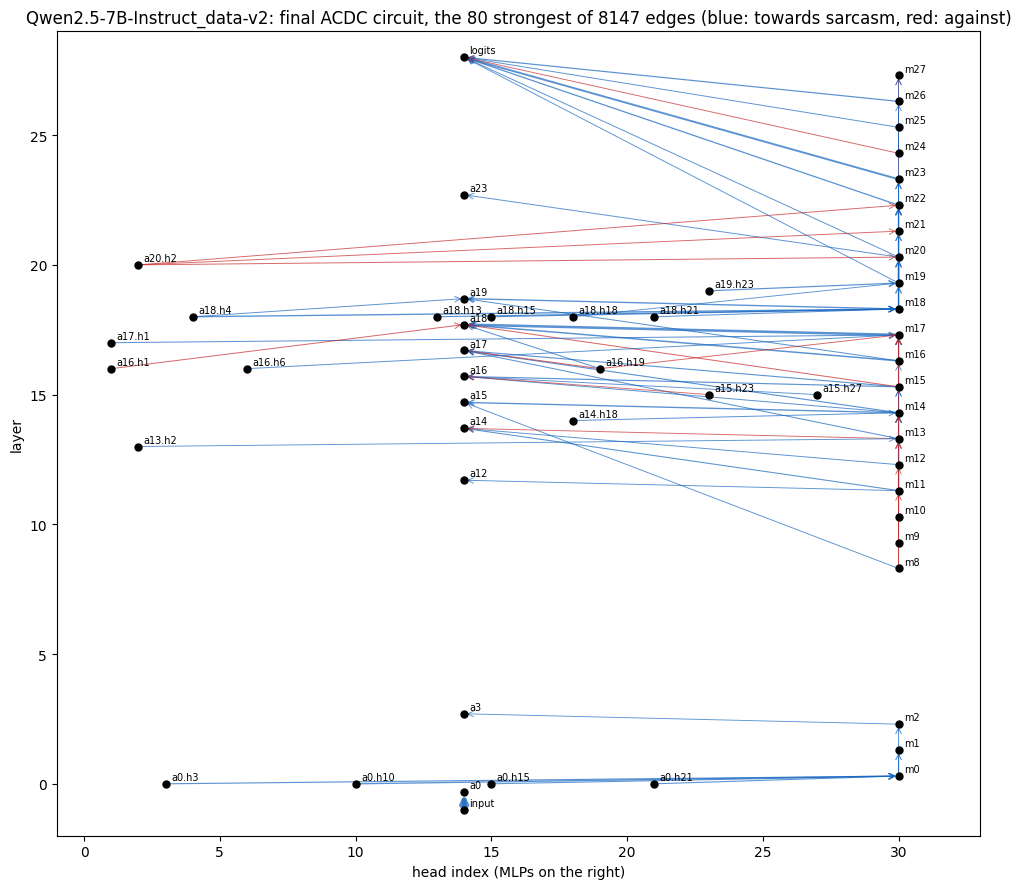

In [15]:
def draw(mask, scores, n_max=80, title=""):
    H = G.n_heads
    def pos(name):
        if name == "input": return (H / 2, -1)
        if name == "logits": return (H / 2, L)
        if name.startswith("a") and "." in name:
            l, h = name[1:].split(".h"); return (int(h), int(l))
        if name.startswith("a"): return (H / 2, int(name[1:]) - 0.3)
        return (H + 2, int(name[1:]) + 0.3)
    tab = edge_table({"s": scores}, G, mask).head(n_max)
    lim = np.abs(tab["combined"]).max()
    fig, ax = plt.subplots(figsize=(10, 9))
    for _, r in tab.iterrows():
        (x0, y0), (x1, y1) = pos(r.sender), pos(r.receiver)
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color="#1565C0" if r.combined > 0 else "#C62828",
                                    lw=0.5 + 3 * abs(r.combined) / lim, alpha=0.7))
    for n in set(tab.sender) | set(tab.receiver):
        x, y = pos(n); ax.scatter(x, y, s=25, c="black", zorder=3); ax.text(x + 0.2, y + 0.15, n, fontsize=7)
    ax.set_xlim(-1, H + 5); ax.set_ylim(-2, L + 1)
    ax.set_xlabel("head index (MLPs on the right)"); ax.set_ylabel("layer"); ax.set_title(title)
    plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "circuit_drawing.png"), dpi=150); plt.show()

draw(CIRC, COMBINED, n_max=80,
     title=f"{TAG}: final ACDC circuit, the 80 strongest of {int(CIRC.sum())} edges (blue: towards sarcasm, red: against)")

## Save (for Phase 3 and the comparison with the full model)

In [16]:
d = results_dir(SUB)
np.save(os.path.join(d, "circuit_mask.npy"), CIRC)
for tau, r in RES.items():
    np.save(os.path.join(d, f"acdc_mask_tau{tau}.npy"), r["mask"])
edge_table({"eap_ig": COMBINED}, G, CIRC).to_csv(os.path.join(d, "circuit_edges.csv"), index=False)
NODES.to_csv(os.path.join(d, "circuit_nodes.csv"), index=False)
TAB.to_csv(os.path.join(d, "acdc_results.csv"), index=False)
json.dump(dict(model=MODEL, version="v3b", cap_margins={str(k): v for k, v in CAP_MARGINS.items()}, kept={str(t): r["kept"] for t, r in RES.items()}, loss=LOSS, tau_star=TAU_STAR, caps={str(k): v for k, v in CAPS.items()}, start_loss=float(START_LOSS), taus=TAUS,
               n_acdc_pairs=len(ACDC_PAIRS), n_monitor_pairs=len(MON_PAIRS),
               v1_edges=None if V1 is None else int(V1.sum()),
               v1_validation_F=None if V1 is None else {e: float(VALP["acdc v1"][e].mean()) for e in EXPS},
               monitor={str(t): [(int(a), int(b), {k: float(x) for k, x in c.items()}) for a, b, c in r["monitor"]] for t, r in RES.items()},
               n_edges=int(CIRC.sum()), n_candidate=int(CAND.sum()), n_graph=G.n_edges(),
               n_components=len(NODES), n_tests={str(t): r["n_tests"] for t, r in RES.items()},
               validation_F={e: float(VALP[f"acdc {TAU_STAR}"][e].mean()) for e in EXPS}, validation_pairs=WHERE),
          open(os.path.join(d, "summary.json"), "w"), indent=1)
print("saved to", d)

saved to /content/drive/MyDrive/sarcasm/02_acdc/Qwen2.5-7B-Instruct_data-v2/v3b
